## Exploratory Data Analysis (EDA) - Diwali Sales Data

## 1. Project Overview & Meaningful Questions
Before writing analytical code, we formulate key business questions to guide the exploration:

1. **Gender Demographics:** Who spends more total money and places more orders—Male or Female buyers?
2. **Age Group Segmentation:** Which specific age bracket contributes the largest share of sales revenue?
3. **Geographic Distribution:** Which top 5 states generate the highest purchasing volume and revenue?
4. **Professional Background:** Which occupational sectors (e.g., IT, Healthcare, Aviation) have the highest spending capacity?
5. **Product Category Performance:** Which product lines generate the maximum sales revenue?
6. **Marital Status Impact:** Does marital status influence purchasing volume across genders?

In [15]:
# import python libraries

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [16]:
# import csv file
df = pd.read_csv('Sales Data.csv', encoding= 'unicode_escape')

In [18]:
df.shape

(11251, 15)

In [4]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.9 MB


In [6]:
#drop unrelated/blank columns
df.drop(['Status', 'unnamed1'], axis=1, inplace=True)

In [7]:
# drop null values
df.dropna(inplace=True)

In [8]:
df.duplicated().sum()

np.int64(8)

In [9]:
df.drop_duplicates(inplace=True)

In [82]:
#check for null values
pd.isnull(df).sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [10]:
# change data type
df['Amount'] = df['Amount'].astype('int')

In [11]:
df['Amount'].dtypes

dtype('int64')

In [12]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='str')

In [13]:
# describe() method returns description of the data in the DataFrame (i.e. count, mean, std, etc)
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123100e+04,11231.000000,11231.000000,11231.000000,11231.000000
mean,1.003004e+06,35.411985,0.419998,2.489093,9454.084676
std,1.716055e+03,12.756116,0.493580,1.114880,5221.728074
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003065e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004428e+06,43.000000,1.000000,3.000000,12677.500000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


## Exploratory Data Analysis

## Gender Analysis
### Question 1: Who spends more—Male or Female buyers?

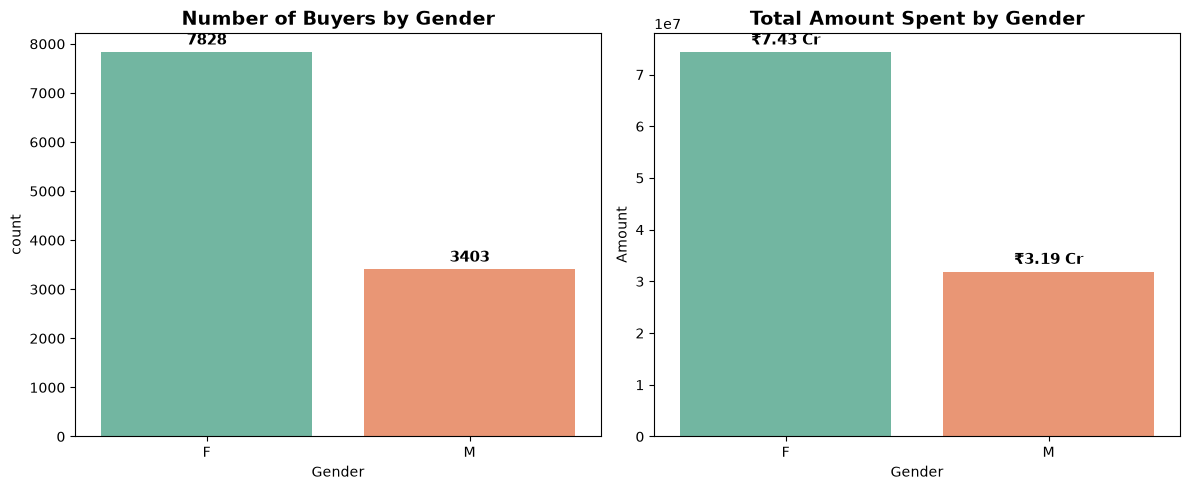

In [14]:
import warnings
warnings.filterwarnings('ignore')
sales_gen = df.groupby(['Gender'], as_index=False)['Amount'].sum()
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
# 1. Number of Buyers by Gender
sns.countplot(x='Gender', data=df, ax=ax[0], palette='Set2')
ax[0].set_title('Number of Buyers by Gender', fontsize=14, fontweight='bold')
for container in ax[0].containers:
    ax[0].bar_label(container, fontsize=11, fontweight='bold', padding=3)

# 2. Total Amount Spent by Gender
sns.barplot(x='Gender', y='Amount', data=sales_gen, ax=ax[1], palette='Set2')
ax[1].set_title('Total Amount Spent by Gender', fontsize=14, fontweight='bold')
for container in ax[1].containers:
    ax[1].bar_label(container, labels=[f'₹{v/1e7:.2f} Cr' for v in container.datavalues], fontsize=11, fontweight='bold', padding=3)
plt.tight_layout()
plt.show()

## Age Group Analysis
### Question 2: Which age bracket contributes the largest share of sales revenue? 

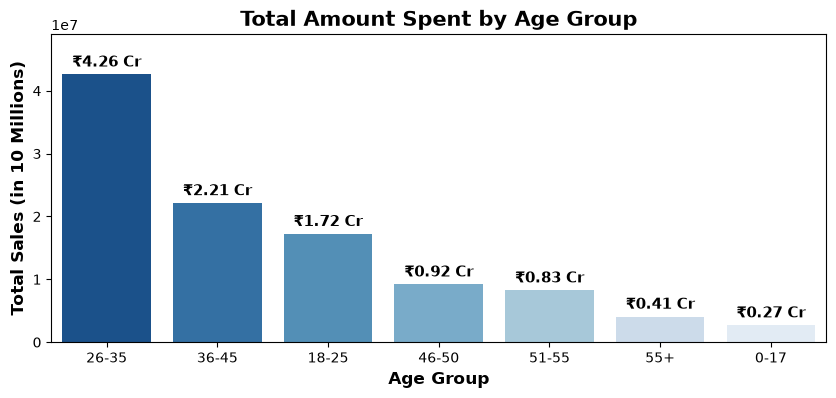

In [15]:
sales_age = df.groupby(['Age Group'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)
plt.figure(figsize=(10, 4))
ax=sns.barplot(x='Age Group', y='Amount', data=sales_age, palette='Blues_r')
plt.title('Total Amount Spent by Age Group', fontsize=15, fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, labels=[f'₹{v/1e7:.2f} Cr' for v in container.datavalues], fontsize=11, fontweight='bold', padding=3)
plt.xlabel('Age Group',fontsize=12, fontweight='bold')
plt.ylabel('Total Sales (in 10 Millions)',fontsize=12, fontweight='bold')
plt.ylim(0, sales_age['Amount'].max() * 1.15)
plt.show()

## Geographic Distribution
### Question 3: Which top 10 states generate the highest purchasing volume and revenue?

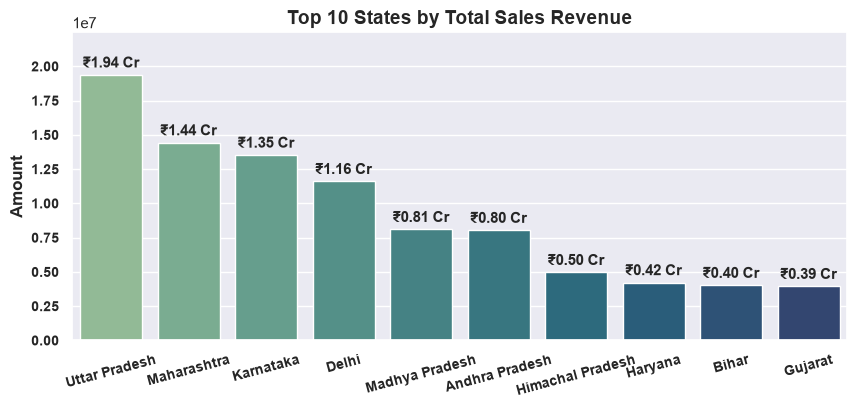

In [79]:
sales_state = df.groupby(['State'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)
plt.figure(figsize=(10, 4))
ax=sns.barplot(x='State', y='Amount', data=sales_state, palette='crest')
plt.title('Top 10 States by Total Sales Revenue',fontsize=14, fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, labels=[f'₹{v/1e7:.2f} Cr' for v in container.datavalues], fontsize=11, fontweight='bold', padding=3)
plt.ylim(0, sales_state['Amount'].max() *1.16)
plt.xticks(rotation=15,fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.xlabel('')
plt.ylabel('Amount',fontsize=12, fontweight='bold')
plt.show()

## Occupation Analysis
### Question 4: Which occupational sectors have the highest spending capacity?

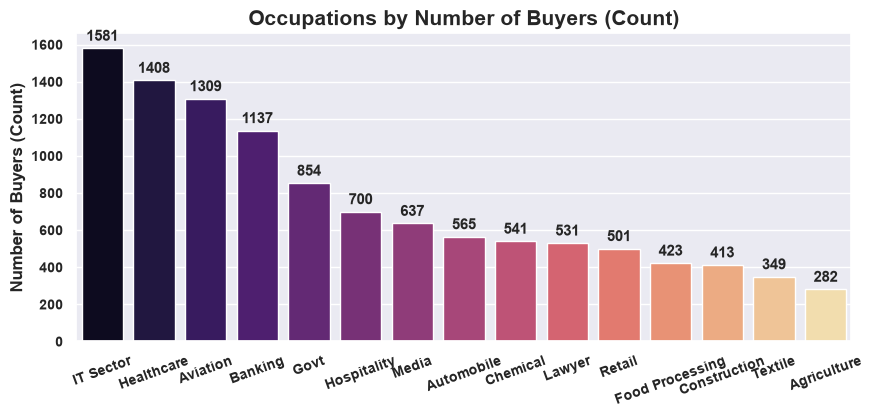

In [97]:
sales_occ = df['Occupation'].value_counts().index
plt.figure(figsize=(10, 4))
ax = sns.countplot(
    x='Occupation', 
    data=df, 
    order=sales_occ, 
    palette='magma'
)
plt.title('Occupations by Number of Buyers (Count)', fontsize=15, fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, fontsize=11, fontweight='bold', padding=3)
plt.xticks(rotation=20,fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.ylabel('Number of Buyers (Count)',fontsize=12, fontweight='bold')
plt.xlabel('')
plt.show()

## Product Category Performance
## Question 5: Which product lines generate the maximum sales revenue?

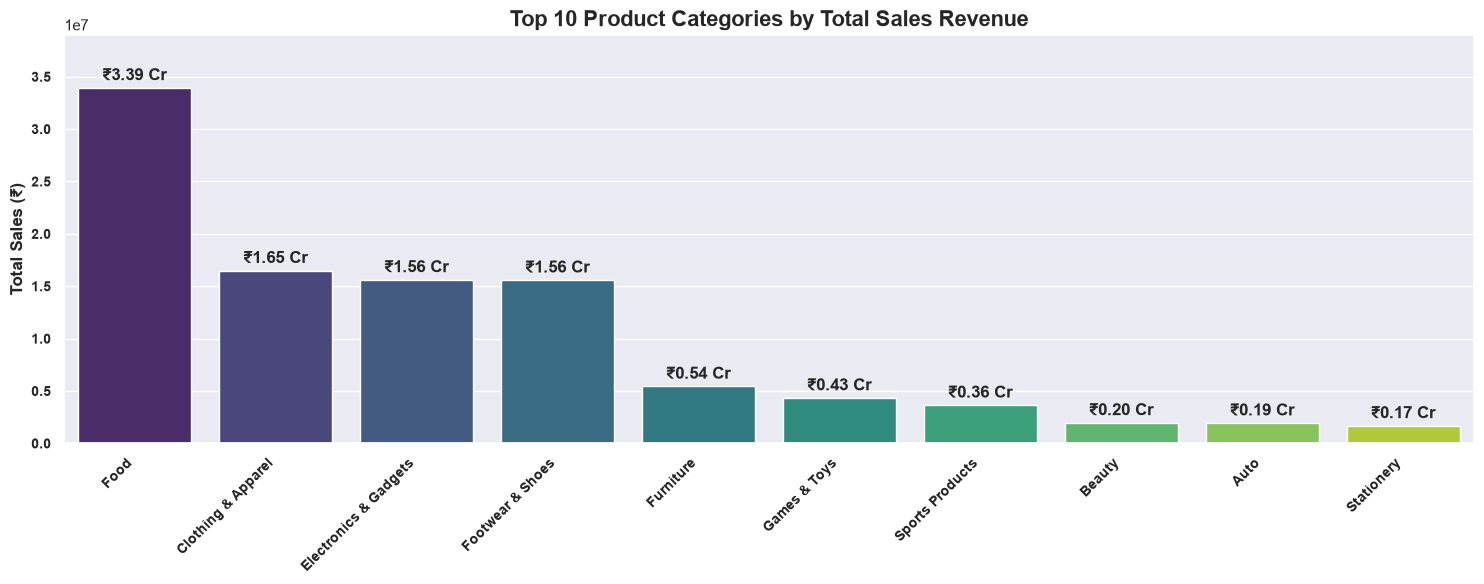

In [92]:
sales_cat = df.groupby(['Product_Category'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)
plt.figure(figsize=(15, 6))
ax = sns.barplot(x='Product_Category', y='Amount', data=sales_cat, palette='viridis')
plt.title('Top 10 Product Categories by Total Sales Revenue', fontsize=16, fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, labels=[f'₹{v/1e7:.2f} Cr' for v in container.datavalues], fontsize=12, fontweight='bold', padding=3)
plt.ylim(0, sales_cat['Amount'].max() * 1.15)
plt.xticks(rotation=45, ha='right', fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.ylabel('Total Sales (₹)', fontsize=12, fontweight='bold')
plt.xlabel('')
plt.tight_layout()
plt.show()

### Question 6 (Marital Status)
- ## Sales Amount by Marital Status & Gender

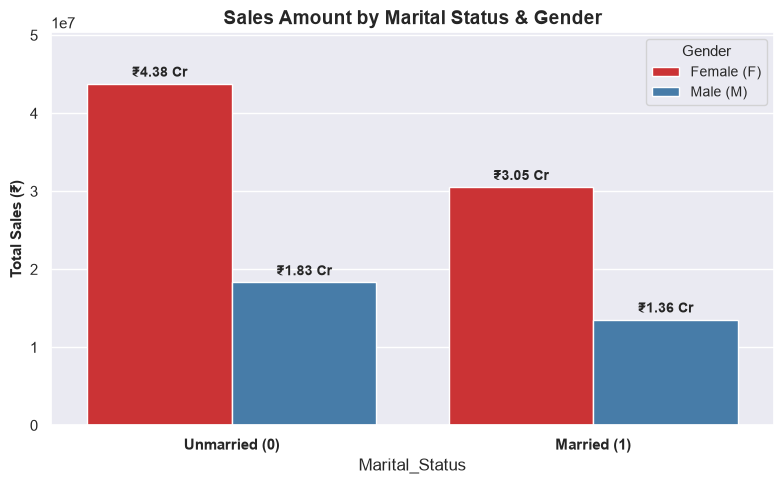

In [96]:
sales_marital = df.groupby(['Marital_Status', 'Gender'], as_index=False)['Amount'].sum()

plt.figure(figsize=(8, 5))
ax = sns.barplot(x='Marital_Status', y='Amount', hue='Gender', data=sales_marital, palette='Set1')
plt.title('Sales Amount by Marital Status & Gender', fontsize=16, fontweight='bold')
plt.xticks(ticks=[0, 1], labels=['Unmarried (0)', 'Married (1)'], fontsize=11, fontweight='bold')
plt.ylabel('Total Sales (₹)', fontsize=11, fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, labels=[f'₹{v/1e7:.2f} Cr' for v in container.datavalues], fontsize=10, fontweight='bold', padding=3)
plt.ylim(0, sales_marital['Amount'].max() * 1.15)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['Female (F)', 'Male (M)'], title='Gender', fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()

## Final Summary & Business Insights
Based on the exploratory analysis:
- **Primary Customer Persona:** The core buyer profile is **married women aged 26–35 years** working in the **IT, Healthcare, and Aviation** sectors.
- **Top Geographies:** Marketing budgets and regional campaigns should prioritize **Uttar Pradesh, Maharashtra, Karnataka, and Delhi**.
- **Inventory Focus:** Stock planning for festival periods should heavily allocate resources to **Food**, **Clothing**, and **Electronics.
- **The primary customer segment driving maximum revenue is unmarried women aged 26–35 years, followed by married women**.